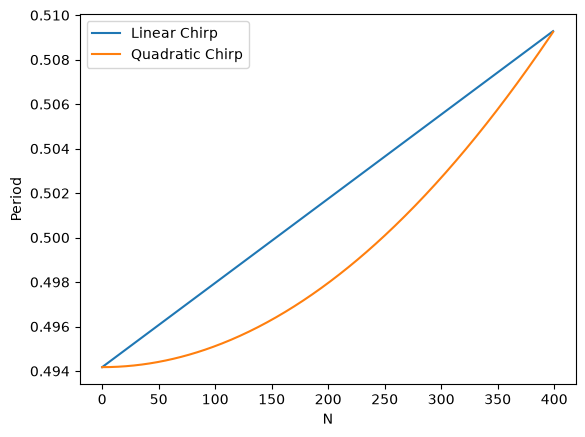

In [1]:
from gratings import rouard
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

def quadratic_chirp(period_1, period_2, N, ratio_at_half=0.25):
    '''Ratio at half is C(N/2)=ratio_at_half * (period_2 - period_1) where C(N) is the chirp at N'''
    cN = period_2 - period_1
    cN2 = ratio_at_half * cN
    A = 2 * ( cN - 2 * cN2 ) / ( N ** 2 )
    B = ( cN - A * N ** 2 ) / N
    
    p = np.arange(0, N)
    return A * p ** 2 + B * p + period_1

def period_to_lengths(periods, duty_cycle=0.5):
    return np.concat(np.stack((duty_cycle * periods, (1 - duty_cycle) * periods), axis=-1))

dB = lambda frac: 10 * np.log10(frac)

neffs = xr.load_dataarray('neffs/neff_interp_220nm_SiN.nc')

width_high = 2
width_low = 1

wl = np.linspace(1.5, 1.6, 1000)

wl_1 = 1.535
wl_2 = 1.575

N = 400

period_1 = wl_1 / ( 4 * float(neffs.interp(width=width_low, wavelength=wl_1).data) ) \
                   + wl_1 / ( 4 * float(neffs.interp(width=width_high, wavelength=wl_1).data) )

period_2 = wl_2 / (4 * float(neffs.interp(width=width_low, wavelength=wl_2).data)) \
                   + wl_2 / ( 4 * float(neffs.interp(width=width_high, wavelength=wl_2).data))


lengths_linear = period_to_lengths(quadratic_chirp(period_1, period_2, N, ratio_at_half=0.5))
lengths_quad = period_to_lengths(quadratic_chirp(period_1, period_2, N, ratio_at_half=0.25))


plt.plot(2 * lengths_linear[::2], label='Linear Chirp')
plt.plot(2 * lengths_quad[::2], label='Quadratic Chirp')
plt.ylabel('Period')
plt.xlabel('N')
plt.legend()
plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
/var/folders/00/ljm0kfhn4fj5k8p84fdc4wd00000gn/T/ipykernel_26040/370907867.py:16: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
/var/folders/00/ljm0kfhn4fj5k8p84fdc4wd00000gn/T/ipykernel_26040/1659414069.py:19: RuntimeWarning: divide by zero encountered in log10
  dB = lambda frac: 10 * np.log10(frac)
/var/folders/00/ljm0kfhn4fj5k8p84fdc4wd00000gn/T/ipykernel_26040/1659414069.py:19: RuntimeWarning: invalid value encountered in log10
  dB = lambda frac: 10 * np.log10(frac)


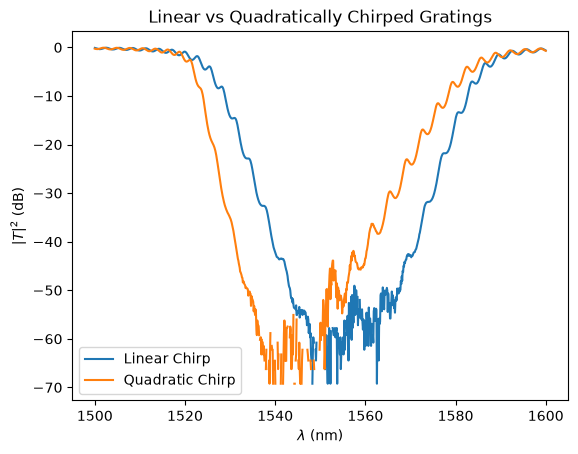

In [2]:
n_high = neffs.interp(width=[width_high], wavelength=wl).data.T[0]
n_low = neffs.interp(width=[width_low], wavelength=wl).data.T[0]

ns = np.vstack(N * (n_high, n_low)).T

S_linear = rouard(wl, lengths_linear, ns)
reflectance_linear = np.array([ np.abs( s[0,1] / s[1,1] ) ** 2 for s in S_linear ])
plt.plot(1e3 * wl, dB(1 - reflectance_linear), label='Linear Chirp')

S_quad = rouard(wl, lengths_quad, ns)
reflectance_quad = np.array([ np.abs( s[0,1] / s[1,1] ) ** 2 for s in S_quad ])
plt.plot(1e3 * wl, dB(1 - reflectance_quad), label='Quadratic Chirp')

plt.title('Linear vs Quadratically Chirped Gratings')
plt.ylabel('$|T|^2$ (dB)')
plt.xlabel('$\lambda$ (nm)')
plt.legend()
# plt.savefig('analytical_vs_rouard.png', dpi=300)
plt.show()